# Лабораторная работа 1. Анализ Big Data-сценария и выбор технологий

**Вариант 4 — IoT Sensor Data. Сценарий №4 задания — анализ логов и мониторинг.** Целевой результат пилота: снизить Mean Time To Repair (MTTR) на 40% за счёт раннего обнаружения аномалий в телеметрии и логах.

Notebook выполняет полное профилирование Kaggle CSV и сравнивает исходный CSV с полными Parquet/Avro serialize/read-back round-trips. Все производственные тарифы, incident rates, event rate и SLA, которых нет в наборе, помечены как **предположения/сценарии**. Обнаруженный в датасете `HH_jit_L0.1_mean` — сетевой jitter-признак, а не метка времени.

## 0. Источник, сценарий и воспроизводимость

Источник по варианту: [Kaggle IoT Dataset for Intrusion Detection Systems (IDS)](https://www.kaggle.com/datasets/azalhowaide/iot-dataset-for-intrusion-detection-systems-ids), файл `BoTNeTIoT-L01-v2.csv`. Большие данные не включены в Git. Войдите в Kaggle, скачайте ZIP, поместите CSV в `data/raw/ids/BoTNeTIoT-L01-v2.csv`; подробные команды — в [README](README.md). По Data Card, `label=1` означает `Attack=Normal`, `label=0` — атаку.

Сценарий №4 требует мониторинга **неструктурированных логов**, своевременной аномалии и сокращения MTTR на 40%. Этот CSV содержит агрегированные числовые сетевые признаки и категориальные поля, но не сырой syslog и не время событий. Поэтому он подходит для фактического анализа структуры/качества/объёма, но не доказывает реальные EPS, календарную динамику или latency. Частотные расчёты ниже — отдельная воспроизводимая replay-модель с объявленными параметрами.

In [1]:
from pathlib import Path
import json, math, os, sys, time, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
LAB1 = ROOT / "lab1"
RESULTS = Path(os.environ.get("LAB1_RESULTS_DIR", LAB1 / "results")).resolve()
RUNTIME = Path(os.environ.get("LAB1_RUNTIME_DIR", ROOT / "data" / "lab1")).resolve()
SOURCE = Path(os.environ.get("LAB1_SOURCE_CSV", ROOT / "data/raw/ids/BoTNeTIoT-L01-v2.csv")).resolve()
FORCE = os.environ.get("LAB1_FORCE", "0") == "1"
RESULTS.mkdir(parents=True, exist_ok=True)
RUNTIME.mkdir(parents=True, exist_ok=True)
get_ipython().run_line_magic("matplotlib", "inline")
if str(LAB1) not in sys.path:
    sys.path.insert(0, str(LAB1))
if not SOURCE.is_file():
    raise FileNotFoundError(f"Нет Kaggle CSV: {SOURCE}. Скачайте его по инструкции в lab1/README.md")

from analyze_ids import analyze_source

# Единственный полный проход анализатора. Его проверенный cache можно повторно использовать.
profile = analyze_source(SOURCE, RUNTIME, RESULTS, force=FORCE)
assert profile.get("status") in {"complete", "complete_with_quality_findings"}, "Анализатор не подтвердил полный профиль и format round-trips"
source_info = profile["source"]
schema = profile["schema"]
source_bytes = int(source_info["bytes"])
row_count = int(source_info["rows"])
column_count = int(source_info["columns"])
assert "azalhowaide/iot-dataset-for-intrusion-detection-systems-ids" in source_info["dataset_id"]
assert source_info["source_file"] == "BoTNeTIoT-L01-v2.csv"
assert schema.get("timestamp_columns", []) == [], "Подтвердите timestamp schema: сценарные velocity расчёты изменятся"
print(f"{row_count:,} строк × {column_count} полей; {source_bytes:,} B ({source_bytes/2**30:.3f} GiB)")
print("SHA-256:", source_info["sha256"])
print("Числовые / категориальные / метка / timestamp:", len(schema["numeric_columns"]), len(schema["categorical_columns"]), schema["label_column"], schema.get("timestamp_columns", []))
print("Полный профиль: PASS; исходный CSV — baseline, Parquet/Avro full round-trips должны пройти.")
if profile["status"] == "complete_with_quality_findings":
    print("Data quality findings присутствуют, анализ сохранён и они перечисляются в разделе Veracity:")
    display(profile.get("quality_findings", profile.get("quality", {})))
category_path = RESULTS / profile["artifacts"]["category_counts"]
category_counts = pd.read_csv(category_path)
assert set(category_counts.columns) == {"column","value","rows"}, category_counts.columns.tolist()

[Lab 1 IDS] +1.7s source SHA-256 verified (1,678,174,220 bytes)


[Lab 1 IDS] +1.7s reusing complete cached profile


7,062,606 строк × 27 полей; 1,678,174,220 B (1.563 GiB)
SHA-256: e3cb8a91f0fb99afb81fefe55ee04743ed67dd7ec9ea4d119cf2a71c8a1a494d
Числовые / категориальные / метка / timestamp: 23 3 label []
Полный профиль: PASS; исходный CSV — baseline, Parquet/Avro full round-trips должны пройти.
Data quality findings присутствуют, анализ сохранён и они перечисляются в разделе Veracity:


{'nulls_by_column': [{'column': 'MI_dir_L0.1_weight', 'missing': 0},
  {'column': 'MI_dir_L0.1_mean', 'missing': 0},
  {'column': 'MI_dir_L0.1_variance', 'missing': 0},
  {'column': 'H_L0.1_weight', 'missing': 0},
  {'column': 'H_L0.1_mean', 'missing': 0},
  {'column': 'H_L0.1_variance', 'missing': 0},
  {'column': 'HH_L0.1_weight', 'missing': 0},
  {'column': 'HH_L0.1_mean', 'missing': 0},
  {'column': 'HH_L0.1_std', 'missing': 0},
  {'column': 'HH_L0.1_magnitude', 'missing': 0},
  {'column': 'HH_L0.1_radius', 'missing': 0},
  {'column': 'HH_L0.1_covariance', 'missing': 0},
  {'column': 'HH_L0.1_pcc', 'missing': 0},
  {'column': 'HH_jit_L0.1_weight', 'missing': 0},
  {'column': 'HH_jit_L0.1_mean', 'missing': 0},
  {'column': 'HH_jit_L0.1_variance', 'missing': 0},
  {'column': 'HpHp_L0.1_weight', 'missing': 0},
  {'column': 'HpHp_L0.1_mean', 'missing': 0},
  {'column': 'HpHp_L0.1_std', 'missing': 0},
  {'column': 'HpHp_L0.1_magnitude', 'missing': 0},
  {'column': 'HpHp_L0.1_radius', 'm

## Сценарий и KPI

**Бизнес-сценарий:** обнаруживать аномальные потоки/сбои по телеметрии и неструктурированным логам, создавать actionable alert и помогать дежурному инженеру локализовать инцидент. Цель задания — MTTR −40%; численное исходное MTTR надо получить у оператора, в Kaggle наборе его нет.

**Предлагаемый пилотный SLA (проектное требование, не измеренный факт):** X = **5000 ms**; p95 от поступления сырого события до алерта ≤X, p99 ≤30 секунд, доступность канала ≥99.5%. Потерянный/пропущенный алерт рассматриваем в ROI по ожидаемому ущербу; ложный алерт — стоимость времени инженера. До production требуется нагрузочный replay на сырых логах и подтверждённых инцидентах.

## 1. Volume — объём данных

### 1.1. Измеренный размер и структура

In [2]:
format_rows = []
for fmt, item in profile["formats"].items():
    equal = item.get("roundtrip", {}).get("all_values_equal", item.get("all_values_equal"))
    if fmt != "csv":
        assert equal is True, f"{fmt} full round-trip не доказан"
    format_rows.append({
        "Формат / codec": fmt,
        "байт": int(item["bytes"]),
        "MiB": int(item["bytes"])/2**20,
        "vs source CSV": int(item["bytes"])/source_bytes,
        "full-value equality": equal,
        "method": item.get("method", "full serialization and read-back"),
        "значения/hash": item.get("roundtrip", {}).get("sha256_roundtrip"),
    })
format_table = pd.DataFrame(format_rows).sort_values("байт")
display(pd.DataFrame([{
    "source": source_info["source_file"], "rows": row_count, "columns": column_count,
    "source bytes": source_bytes, "MiB": source_bytes/2**20, "GiB": source_bytes/2**30,
    "rows / file byte": row_count/source_bytes,
    "mean file bytes / row (includes CSV delimiters/header)": source_bytes/row_count,
    "SHA-256": source_info["sha256"],
}]))
display(format_table)
csv_bytes = source_bytes
parquet_bytes = int(profile["formats"]["parquet"]["bytes"])
avro_bytes = int(profile["formats"]["avro"]["bytes"])
parquet_ratio = parquet_bytes/csv_bytes
avro_ratio = avro_bytes/csv_bytes
print(f"Parquet/source CSV = {parquet_ratio:.3f} ({(1-parquet_ratio)*100:.1f}% экономии); Avro/source CSV = {avro_ratio:.3f} ({(1-avro_ratio)*100:.1f}% экономии).")
print("CSV — исходный Kaggle файл. Parquet и Avro сериализованы и прочитаны обратно; проверено равенство всех значений, не только числа строк. Elapsed time здесь не сравнивается: Parquet read timing может включать только SELECT count(*), тогда как equality проверяется отдельно; Avro read timing включает полный digest.")

,source,rows,columns,source bytes,MiB,GiB,rows / file byte,mean file bytes / row (includes CSV delimiters/header),SHA-256
0,BoTNeTIoT-L01-v2.csv,7062606,27,1678174220,1600.431652,1.562922,0.004209,237.614022,e3cb8a91f0fb99afb81fefe55ee04743ed67dd7ec9ea4d...


,Формат / codec,байт,MiB,vs source CSV,full-value equality,method,значения/hash
2,avro,370939358,353.755339,0.221037,True,streaming typed records; full-row canonical di...,None
1,parquet,458856825,437.599969,0.273426,True,DuckDB full typed conversion; bidirectional EX...,None
0,csv,1678174220,1600.431652,1.000000,None,original source file; no self-roundtrip claimed,None


Parquet/source CSV = 0.273 (72.7% экономии); Avro/source CSV = 0.221 (77.9% экономии).
CSV — исходный Kaggle файл. Parquet и Avro сериализованы и прочитаны обратно; проверено равенство всех значений, не только числа строк. Elapsed time здесь не сравнивается: Parquet read timing может включать только SELECT count(*), тогда как equality проверяется отдельно; Avro read timing включает полный digest.


**Вывод по текущему файлу.** Ниже таблица сравнивает реальные сериализации. Это один статический снимок, а не история прироста. В первую очередь выбираем columnar Parquet для аналитики, Avro — для schema-controlled record interchange; raw source храним неизменённым для аудита.

### 1.2. Прогноз объёма: явный replay-профиль

У исходного CSV нет event-time, поэтому ежедневный прирост и дату пересечения 1 ТБ нельзя измерить в нём. Для планирования задаём базовый поток **100 событий/с** и **1000 событий/с на пике (10×)**. В этой модели 18 пиковых 5-минутных окон в сутки дают взвешенное среднее **156.25 событий/с**; оба объёма показаны как разные sensitivity сценарии. Запись на диске оцениваем как наблюдаемый средний размер CSV-строки исходного набора; этот размер является лишь прокси для будущего формата логов. Цель throughput отдельного worker в sizing далее — гипотеза, которую надо нагрузочно проверить.

,показатель,значение,происхождение
0,Base replay input,100 events/s,scenario
1,Peak replay input,"1,000 events/s",scenario: 10×
2,Средний EPS суточного replay профиля,156.25 events/s,scenario weighted average: 18 peak windows/day
3,Serialized CSV proxy / event,237.61 B,наблюдаемый source_bytes / rows
4,Событий за сутки,"8,640,000",scenario
5,CSV-proxy прирост за сутки,1.91 GiB,scenario
6,Parquet-proxy прирост за сутки,0.52 GiB,scenario × measured format ratio
7,CSV-proxy объём за год,0.68 TiB,"scenario, no retention"
8,Parquet-proxy объём за год,0.19 TiB,"scenario, no retention"
9,Время до 1 TB decimal raw,487.1 days,"scenario, constant base EPS"


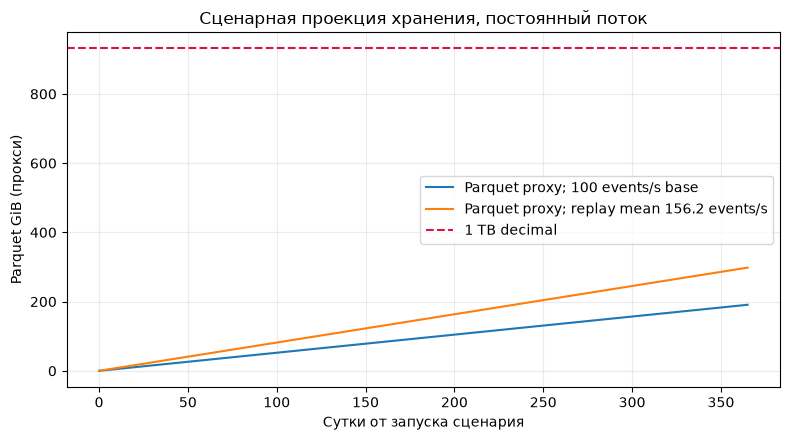

In [3]:
BASE_EPS = 100.0       # сценарное допущение
PEAK_EPS = 1_000.0     # 10x сценарный burst
SECONDS_DAY = 86_400
TARGET_TB_BYTES = 10**12
# Six 15-minute bursts in a day: 18 replay windows × 5 minutes.
REPLAY_PEAK_SECONDS_PER_DAY = 6*3*300
REPLAY_MEAN_EPS = (BASE_EPS*(SECONDS_DAY-REPLAY_PEAK_SECONDS_PER_DAY)+PEAK_EPS*REPLAY_PEAK_SECONDS_PER_DAY)/SECONDS_DAY
record_bytes = source_bytes / row_count
daily_events = BASE_EPS * SECONDS_DAY
daily_raw_bytes = daily_events * record_bytes
daily_parquet_bytes = daily_raw_bytes * parquet_ratio
replay_daily_events = REPLAY_MEAN_EPS*SECONDS_DAY
replay_daily_raw_bytes = replay_daily_events*record_bytes
replay_daily_parquet_bytes = replay_daily_raw_bytes*parquet_ratio
year_events = daily_events * 365
year_raw_bytes = daily_raw_bytes * 365
year_parquet_bytes = daily_parquet_bytes * 365
days_to_1tb = TARGET_TB_BYTES / daily_raw_bytes
replay_days_to_1tb = TARGET_TB_BYTES/replay_daily_raw_bytes
projection = pd.DataFrame([
    {"показатель": "Base replay input", "значение": f"{BASE_EPS:,.0f} events/s", "происхождение": "scenario"},
    {"показатель": "Peak replay input", "значение": f"{PEAK_EPS:,.0f} events/s", "происхождение": "scenario: 10×"},
    {"показатель": "Средний EPS суточного replay профиля", "значение": f"{REPLAY_MEAN_EPS:,.2f} events/s", "происхождение": "scenario weighted average: 18 peak windows/day"},
    {"показатель": "Serialized CSV proxy / event", "значение": f"{record_bytes:,.2f} B", "происхождение": "наблюдаемый source_bytes / rows"},
    {"показатель": "Событий за сутки", "значение": f"{daily_events:,.0f}", "происхождение": "scenario"},
    {"показатель": "CSV-proxy прирост за сутки", "значение": f"{daily_raw_bytes/2**30:,.2f} GiB", "происхождение": "scenario"},
    {"показатель": "Parquet-proxy прирост за сутки", "значение": f"{daily_parquet_bytes/2**30:,.2f} GiB", "происхождение": "scenario × measured format ratio"},
    {"показатель": "CSV-proxy объём за год", "значение": f"{year_raw_bytes/2**40:,.2f} TiB", "происхождение": "scenario, no retention"},
    {"показатель": "Parquet-proxy объём за год", "значение": f"{year_parquet_bytes/2**40:,.2f} TiB", "происхождение": "scenario, no retention"},
    {"показатель": "Время до 1 TB decimal raw", "значение": f"{days_to_1tb:,.1f} days", "происхождение": "scenario, constant base EPS"},
    {"показатель": "Время до 1 TB decimal raw при среднем replay EPS", "значение": f"{replay_days_to_1tb:,.1f} days", "происхождение": "scenario, weighted replay average"},
])
display(projection)
days = np.arange(0, 366)
growth_gib = days * daily_parquet_bytes / 2**30
replay_growth_gib = days*replay_daily_parquet_bytes/2**30
plt.figure(figsize=(8,4.5)); plt.plot(days, growth_gib, label="Parquet proxy; 100 events/s base")
plt.plot(days,replay_growth_gib,label=f"Parquet proxy; replay mean {REPLAY_MEAN_EPS:.1f} events/s")
plt.axhline(10**12/2**30, color="crimson", ls="--", label="1 TB decimal")
plt.xlabel("Сутки от запуска сценария"); plt.ylabel("Parquet GiB (прокси)"); plt.title("Сценарная проекция хранения, постоянный поток")
plt.grid(alpha=.25); plt.legend(); plt.tight_layout(); plt.savefig(RESULTS/"volume_growth.png", dpi=150); plt.show()

### 1.3. Архив и стоимость хранения

Требуемая hot window — **30 дней** (предположение, подлежащее сверке с расследованиями). Raw сохраняется immutable, curated Parquet — с partitioning по дате ingestion и версии схемы. Старше hot window данные переводятся в cold tier, если инцидентный retention contract это разрешает.

Расчёт использует только иллюстративные примеры официальной [страницы тарифов Yandex Object Storage](https://yandex.cloud/ru/docs/storage/pricing), проверенные 20.10.2026: Standard 2.376 ₽/GiB·month, Ice 0.6336 ₽/GiB·month; 1 GiB Standard бесплатно в месяц; Ice оплачивается минимум 12 месяцев; ставки примера включают НДС. Это ориентир, не актуальная коммерческая котировка. Запросы, исходящий трафик, репликация и compute исключены. Расчёт daily-average balance учитывает наращивание хранилища внутри каждого календарного месяца; отдельно приведён steady-state: годовой объём хранится 12 месяцев.

In [4]:
STANDARD_RUB_GIB_MONTH = 2.376
ICE_RUB_GIB_MONTH = 0.6336
FREE_STANDARD_GIB_MONTH = 1.0
monthly_storage = []
daily_balance = np.arange(1, 366) * daily_parquet_bytes / 2**30
replay_daily_balance = np.arange(1,366)*replay_daily_parquet_bytes/2**30
for month in range(1, 13):
    start = sum([31,28,31,30,31,30,31,31,30,31,30,31][:month-1])
    end = sum([31,28,31,30,31,30,31,31,30,31,30,31][:month])
    avg_gib = float(daily_balance[start:end].mean())
    replay_avg_gib = float(replay_daily_balance[start:end].mean())
    month_new_gib = (end-start)*daily_parquet_bytes/2**30
    replay_month_new_gib=(end-start)*replay_daily_parquet_bytes/2**30
    monthly_storage.append({
        "месяц": month, "дней": end-start,
        "100 EPS: средний остаток, GiB": avg_gib,
        "100 EPS: Standard, ₽": max(avg_gib-FREE_STANDARD_GIB_MONTH,0)*STANDARD_RUB_GIB_MONTH,
        "100 EPS: Ice min-12mo commitment, ₽": month_new_gib*12*ICE_RUB_GIB_MONTH,
        "replay mean EPS: средний остаток, GiB": replay_avg_gib,
        "replay mean EPS: Standard, ₽": max(replay_avg_gib-FREE_STANDARD_GIB_MONTH,0)*STANDARD_RUB_GIB_MONTH,
        "replay mean EPS: Ice min-12mo commitment, ₽": replay_month_new_gib*12*ICE_RUB_GIB_MONTH,
    })
storage_table = pd.DataFrame(monthly_storage)
storage_year = storage_table[["100 EPS: Standard, ₽","100 EPS: Ice min-12mo commitment, ₽","replay mean EPS: Standard, ₽","replay mean EPS: Ice min-12mo commitment, ₽" ]].sum()
steady_monthly_gib = year_parquet_bytes/2**30
steady_annual_standard = max(steady_monthly_gib-FREE_STANDARD_GIB_MONTH,0)*STANDARD_RUB_GIB_MONTH*12
steady_annual_ice = steady_monthly_gib*ICE_RUB_GIB_MONTH*12
display(storage_table)
display(pd.DataFrame([
    {"сценарий":"растёт год при 100 EPS: Standard monthly-average; Ice 12mo commitment per monthly lot", "Standard ₽":storage_year["100 EPS: Standard, ₽"], "Ice ₽ (min 12mo)":storage_year["100 EPS: Ice min-12mo commitment, ₽"]},
    {"сценарий":f"растёт год при replay mean {REPLAY_MEAN_EPS:.1f} EPS", "Standard ₽":storage_year["replay mean EPS: Standard, ₽"], "Ice ₽ (min 12mo)":storage_year["replay mean EPS: Ice min-12mo commitment, ₽"]},
    {"сценарий":"100 EPS: годовой объём достигнут сразу и хранится 12 месяцев (steady state)", "Standard ₽":steady_annual_standard, "Ice ₽ (min 12mo)":steady_annual_ice},
]))
storage_table.to_csv(RESULTS/"storage_cost_monthly.csv",index=False)
print("Дисковая стоимость не включает операции, egress, replication, compute; Ice minimum commitment may dominate short retention.")

,месяц,дней,"100 EPS: средний остаток, GiB","100 EPS: Standard, ₽","100 EPS: Ice min-12mo commitment, ₽","replay mean EPS: средний остаток, GiB","replay mean EPS: Standard, ₽","replay mean EPS: Ice min-12mo commitment, ₽"
0,1,31,8.364617,17.498331,123.220849,13.069714,28.677641,192.532577
1,2,28,23.786880,54.141627,111.296251,37.167000,85.932793,173.900392
2,3,31,39.209143,90.784924,123.220849,61.264286,143.187944,192.532577
3,4,30,55.154195,128.670367,119.245983,86.178429,202.383948,186.321849
4,5,31,71.099246,166.555809,123.220849,111.092573,261.579952,192.532577
5,6,30,87.044298,204.441252,119.245983,136.006716,320.775956,186.321849
6,7,31,102.989350,242.326695,123.220849,160.920859,379.971960,192.532577
7,8,31,119.195795,280.833210,123.220849,186.243430,440.138391,192.532577
8,9,30,135.140847,318.718653,119.245983,211.157574,499.334395,186.321849
9,10,31,151.085899,356.604095,123.220849,236.071717,558.530399,192.532577


,сценарий,Standard ₽,Ice ₽ (min 12mo)
0,растёт год при 100 EPS: Standard monthly-avera...,2687.439481,1450.826128
1,растёт год при replay mean 156.2 EPS,4215.162189,2266.915826
2,100 EPS: годовой объём достигнут сразу и храни...,5412.085982,1450.826128


Дисковая стоимость не включает операции, egress, replication, compute; Ice minimum commitment may dominate short retention.


**Критерий перехода Pandas → Spark.** Для данного статического анализа Spark не оправдан только объёмом: важны p95 latency, end-to-end cost и параллелизм. Для выбранной 16 GiB VM задаём численный memory-review gate: pipeline может занимать до 50% RAM (8 GiB), а на преобразования и временные копии закладываем 3× от DataFrame, поэтому порог `8/3 ≈ 2.67 GiB` для полного DataFrame. Это планировочный порог, не универсальный лимит CSV и не доказательство, что Spark быстрее; проверить фактический peak RSS на репрезентативном файле. Переходить на Spark, если DataFrame пересекает этот порог и chunked/DuckDB single-node путь не удовлетворяет времени/стоимости, либо replay на целевом hardware регулярно не укладывается в 5 s p95 alert SLA, worker исчерпывает RAM/disk headroom или не держит минимум 2× peak EPS. Решение подтвердить benchmark одинакового workload и сравнить compute+операционную стоимость.

## 2. Velocity — скорость поступления

### 2.1. Данные не содержат времени события; построение replay-модели

Средний EPS, максимальный 5-минутный объём и CV реальные для датасета **неидентифицируемы**: нет `timestamp`/`event_time`. Далее фиксированный seed создаёт суточную модель Poisson-поступления: 100 EPS в обычные окна и 1000 EPS на 15 минут в начале каждого 4-часового блока. Это проверяемый расчёт для planning, а не измеренная скорость устройств.

,seed,windows,mean events/s,max events / 5 min,max equivalent EPS,CV of 5-min EPS,peak windows,source timestamps
0,20261020,288,156.208264,300708,1002.36,1.397195,18,0


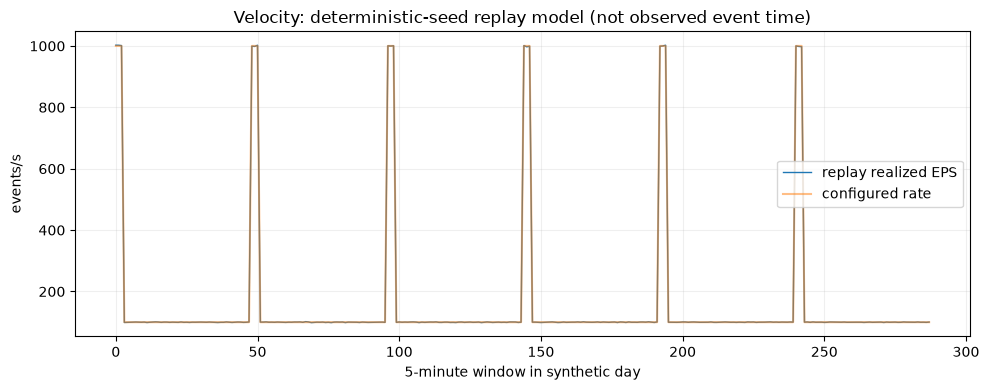

In [5]:
RNG_SEED = 20261020
WINDOW_SECONDS = 300
rng = np.random.default_rng(RNG_SEED)
windows = np.arange(288)
peak_mask = np.zeros(288, dtype=bool)
for start in range(0, 288, 48):
    peak_mask[start:start+3] = True  # 15 min burst every 4 hours (scenario)
rate = np.where(peak_mask, PEAK_EPS, BASE_EPS)
window_events = rng.poisson(rate*WINDOW_SECONDS)
window_eps = window_events/WINDOW_SECONDS
mean_eps = float(window_eps.mean())
peak_5min_events = int(window_events.max())
cv_eps = float(window_eps.std(ddof=1)/mean_eps)
replay = pd.DataFrame({"5-min window":windows,"scenario rate EPS":rate,"generated events":window_events,"realized events/s":window_eps,"peak period":peak_mask})
display(pd.DataFrame([{"seed":RNG_SEED,"windows":len(replay),"mean events/s":mean_eps,"max events / 5 min":peak_5min_events,"max equivalent EPS":peak_5min_events/WINDOW_SECONDS,"CV of 5-min EPS":cv_eps,"peak windows":int(peak_mask.sum()),"source timestamps":len(schema.get("timestamp_columns",[]))}]))
replay.to_csv(RESULTS/"velocity_replay_windows.csv",index=False)
plt.figure(figsize=(10,4)); plt.plot(replay["5-min window"],replay["realized events/s"],lw=1,label="replay realized EPS"); plt.plot(replay["5-min window"],replay["scenario rate EPS"],alpha=.5,label="configured rate")
plt.xlabel("5-minute window in synthetic day"); plt.ylabel("events/s"); plt.title("Velocity: deterministic-seed replay model (not observed event time)"); plt.legend(); plt.grid(alpha=.2); plt.tight_layout(); plt.savefig(RESULTS/"velocity_5min.png",dpi=150); plt.show()

### 2.2. Batch, micro-batch и true-stream latency

Задание требует hourly batch, micro-batch каждые 5 минут и true streaming. Показатели ниже — latency budget при заданных параметрах, а не измеренные задержки CSV. Сравниваем event age до алерта, не только длительность вычисления.

In [6]:
PROCESSING_CAPACITY_EPS = 2_000.0  # целевое provisioned capacity, требует load test
OUTAGE_SECONDS = 30*60
RECOVERY_MARGIN_EPS = PROCESSING_CAPACITY_EPS - PEAK_EPS
outage_events = PEAK_EPS*OUTAGE_SECONDS
outage_bytes = outage_events*record_bytes*parquet_ratio
recovery_seconds = outage_events/RECOVERY_MARGIN_EPS
batch = pd.DataFrame([
 {"режим":"hourly batch","max wait before run, s":3600,"compute budget, s":600,"p95 end-to-alert budget, s":4200,"годится для 5s SLA":False},
 {"режим":"micro-batch every 5 min","max wait, s":300,"compute budget, s":30,"p95 end-to-alert budget, s":330,"годится для 5s SLA":False},
 {"режим":"true streaming","max queue/trigger budget, s":2,"compute budget, s":1,"notify budget, s":2,"p95 end-to-alert budget, s":5,"годится для 5s SLA":True},
])
display(batch)
print(f"30-minute outage at scenario peak {PEAK_EPS:,.0f} EPS: {outage_events:,.0f} events; ~{outage_bytes/2**30:.2f} GiB Parquet proxy backlog.")
print(f"If neither producer nor durable broker persists during that outage, up to {outage_events:,.0f} events / {outage_bytes/2**30:.2f} GiB are lost; with durable acknowledgement the same quantity is buffered backlog, not data loss.")
print(f"After recovery, at {PROCESSING_CAPACITY_EPS:,.0f} EPS capacity and {PEAK_EPS:,.0f} EPS continuing peak input, drain time ≈ {recovery_seconds:.1f} s. Assumes no event loss before durable broker acknowledgement.")
print(f"Target compute capacity for 2× peak headroom: {2*PEAK_EPS:,.0f} EPS; current {PROCESSING_CAPACITY_EPS:,.0f} EPS scenario is 2× configured peak, not an empirical benchmark.")
batch.to_csv(RESULTS/"velocity_modes.csv",index=False)

,режим,"max wait before run, s","compute budget, s","p95 end-to-alert budget, s",годится для 5s SLA,"max wait, s","max queue/trigger budget, s","notify budget, s"
0,hourly batch,3600.0,600,4200,False,NaN,NaN,NaN
1,micro-batch every 5 min,NaN,30,330,False,300.0,NaN,NaN
2,true streaming,NaN,1,5,True,NaN,2.0,2.0


30-minute outage at scenario peak 1,000 EPS: 1,800,000 events; ~0.11 GiB Parquet proxy backlog.
If neither producer nor durable broker persists during that outage, up to 1,800,000 events / 0.11 GiB are lost; with durable acknowledgement the same quantity is buffered backlog, not data loss.
After recovery, at 2,000 EPS capacity and 1,000 EPS continuing peak input, drain time ≈ 1800.0 s. Assumes no event loss before durable broker acknowledgement.
Target compute capacity for 2× peak headroom: 2,000 EPS; current 2,000 EPS scenario is 2× configured peak, not an empirical benchmark.


**Обоснование X для SLA:** 5 s event-to-alert — проектная цель: инцидент обнаруживается быстро относительно человеческого MTTR, а delayed hourly/micro-batch не удовлетворяют цели real-time alert. Источник не содержит задержек сенсоров, стоимости ошибки или incident timeline, поэтому SLA и false alert cost должны подтвердить владельцы эксплуатации. При потере событий брокер должен ack после durable write, хранить как минимум 30 min peak backlog и иметь drain throughput больше продолжающегося входящего EPS.

**Вывод по Velocity:** для алертов требуется true streaming; micro-batch остаётся подходящим для минутных сводок/backfill. Для целевого peak 1000 EPS начинаем sizing с 2000 EPS durable processing capacity и проверяем его нагрузочным тестом. Фактическая производительность не заявляется без такого теста.

## 3. Variety — разнообразие данных

In [7]:
format_profile = pd.read_csv(RESULTS / profile["artifacts"]["format_profile"])
type_counts = pd.DataFrame([
 {"тип":"Числовые признаки", "число полей":len(schema["numeric_columns"]), "поля":", ".join(schema["numeric_columns"])},
 {"тип":"Категориальные", "число полей":len(schema["categorical_columns"]), "поля":", ".join(schema["categorical_columns"])},
 {"тип":"Отдельная метка", "число полей":1, "поля":schema["label_column"]},
 {"тип":"Timestamp", "число полей":len(schema["timestamp_columns"]), "поля":", ".join(schema["timestamp_columns"]) or "отсутствуют"},
])
display(type_counts)
display(format_profile)
display(pd.DataFrame([profile["variety"]]))
print("Nested JSON fields:", profile["variety"].get("nested_structures", []))
print("Format/schema issues:", profile["variety"].get("format_issues", []))
print("Numeric features:", schema["numeric_columns"])
print("Category fields:", schema["categorical_columns"])

,тип,число полей,поля
0,Числовые признаки,23,"MI_dir_L0.1_weight, MI_dir_L0.1_mean, MI_dir_L..."
1,Категориальные,3,"Device_Name, Attack, Attack_subType"
2,Отдельная метка,1,label
3,Timestamp,0,отсутствуют


,field,value,note
0,timestamp_columns,0.000000e+00,The original header contains no timestamp column.
1,numeric_columns,2.300000e+01,23 engineered numeric features; HH_jit_L0.1_me...
2,categorical_columns,4.000000e+00,"Device_Name, Attack, Attack_subType, and label."
3,categorical_text_bytes,2.645561e+08,UTF-8 payload bytes across the three categoric...
4,categorical_text_share_of_csv_bytes,1.576452e-01,Lower-bound text payload share; excludes CSV f...
5,json_like_categorical_cells,0.000000e+00,Categorical fields containing brace or bracket...
6,categorical_values_with_outer_whitespace,0.000000e+00,Text values differing from trim(value); useful...


,structured_columns,numeric_columns,categorical_text_columns,timestamp_columns,nested_structures,note
0,27,23,3,0,0,The file is flat tabular CSV; categorical valu...


Nested JSON fields: 0
Format/schema issues: []
Numeric features: ['MI_dir_L0.1_weight', 'MI_dir_L0.1_mean', 'MI_dir_L0.1_variance', 'H_L0.1_weight', 'H_L0.1_mean', 'H_L0.1_variance', 'HH_L0.1_weight', 'HH_L0.1_mean', 'HH_L0.1_std', 'HH_L0.1_magnitude', 'HH_L0.1_radius', 'HH_L0.1_covariance', 'HH_L0.1_pcc', 'HH_jit_L0.1_weight', 'HH_jit_L0.1_mean', 'HH_jit_L0.1_variance', 'HpHp_L0.1_weight', 'HpHp_L0.1_mean', 'HpHp_L0.1_std', 'HpHp_L0.1_magnitude', 'HpHp_L0.1_radius', 'HpHp_L0.1_covariance', 'HpHp_L0.1_pcc']
Category fields: ['Device_Name', 'Attack', 'Attack_subType']


В CSV реально обнаруживаются типизированные сетевые признаки и категории `Device_Name`, `Attack`, `Attack_subType`, `label`. Это не сырой текст логов; доля unstructured data в целевом production потоке не выводится из данного источника. Для нового syslog-входа предположим, отдельно от IDS CSV, 1.5 KiB/event сырого сообщения и 10% потока в текстовом виде; это только план capacity. Parsing требует формата/regex catalog, timestamp/device correlation, normalization, quarantine и тестовой коллекции реально встречавшихся шаблонов; базовая оценка — две недели инженера на парсер и fixtures (допущение). NLP не нужен до появления доказанного свободного текста, геопространственная обработка не нужна при отсутствии координат.

**Предлагаемая схема хранения:** immutable raw syslog/CSV (compressed, retention/access control); typed curated Parquet с schema version и partition по ingestion date + device/tenant, если измеренный cardinality/запросы это оправдывают; bad records и неизвестные шаблоны в quarantine. Сырые строки не переписывать после parsing, чтобы сохранить forensic evidence. Различать event_time и ingest_time после того, как upstream действительно начнёт их передавать.

## 4. Veracity — достоверность данных

### 4.1. Полнота, пропуски, значения и дубли

In [8]:
quality = profile["quality"]
null_rows = quality.get("nulls_by_column", [])
nulls = {row["column"]:int(row["missing"]) for row in null_rows}
stats_rows = profile["numeric_stats"]
stats = {str(item.get("column",item.get("field"))):item for item in stats_rows}
quality_rows=[]
for col in source_info["column_names"]:
    n_missing = int(nulls.get(col, 0))
    row={"column":col,"dtype":schema["dtypes"].get(col),"missing":n_missing,"missing %":100*n_missing/row_count}
    if col in stats:
        s=stats[col]
        row.update({"NaN":s["nan"],"+Inf":s["positive_infinity"],"-Inf":s["negative_infinity"],"min":s["min"],"max":s["max"],"mean":s["mean"],"std":s["std"]})
    quality_rows.append(row)
quality_table=pd.DataFrame(quality_rows)
display(quality_table)
quality_metrics = pd.read_csv(RESULTS / profile["artifacts"]["quality_metrics"])
display(quality_metrics)
display(pd.DataFrame([{
 "full duplicate excess rows":quality["duplicates"]["full_row_count_excluding_first_occurrence"],
 "duplicate examples":profile["artifacts"].get("duplicate_examples"),
 "label/category consistency":quality.get("label_category_consistency"),
 "Great Expectations critical label":quality.get("critical_label_gx"),
 "repeat-record caveat":quality["duplicates"].get("warning"),
}]))
duplicate_examples_path=RESULTS/profile["artifacts"]["duplicate_examples"]
duplicate_examples=pd.read_csv(duplicate_examples_path)
if not duplicate_examples.empty:
    display(duplicate_examples)
gx_result = quality.get("critical_label_gx", {})
display(pd.DataFrame([gx_result]))
negative_control = gx_result.get("negative_control", {})
assert negative_control.get("tested") is True and negative_control.get("failed_as_expected") is True, "Great Expectations negative control must reject the deliberately invalid critical label"
print(f"Great Expectations: {gx_result.get('expectations_succeeded')}/{gx_result.get('expectations_run')} successful expectations; positive data pass={gx_result.get('expectations_passed')}; negative control rejected invalid label.")
quality_examples_path = RESULTS / profile["artifacts"].get("quality_examples", "quality_examples.csv")
if quality_examples_path.exists():
    quality_examples = pd.read_csv(quality_examples_path)
    print(f"Concrete rule violations / malformed-value examples (first 20 of {len(quality_examples):,}); source_row is a 1-based data-row ordinal (header excluded):")
    display(quality_examples.head(20))
else:
    print("Analyzer emitted no quality_examples.csv; inspect quality_metrics.csv for counts and use duplicate_examples.csv for duplicate examples.")

,column,dtype,missing,missing %,NaN,+Inf,-Inf,min,max,mean,std
0,MI_dir_L0.1_weight,float64,0,0.0,0.0,0.0,0.0,1.000000,8.946997e+03,3.400682e+03,2.897012e+03
1,MI_dir_L0.1_mean,float64,0,0.0,0.0,0.0,0.0,60.000000,1.401994e+03,1.794441e+02,1.537109e+02
2,MI_dir_L0.1_variance,float64,0,0.0,0.0,0.0,0.0,0.000000,4.520011e+05,1.931062e+04,2.636844e+04
3,H_L0.1_weight,float64,0,0.0,0.0,0.0,0.0,1.000000,8.946997e+03,3.400682e+03,2.897012e+03
4,H_L0.1_mean,float64,0,0.0,0.0,0.0,0.0,60.000000,1.401994e+03,1.794441e+02,1.537107e+02
5,H_L0.1_variance,float64,0,0.0,0.0,0.0,0.0,0.000000,4.520011e+05,1.931066e+04,2.636842e+04
6,HH_L0.1_weight,float64,0,0.0,0.0,0.0,0.0,1.000000,7.944987e+03,1.892359e+03,2.523083e+03
7,HH_L0.1_mean,float64,0,0.0,0.0,0.0,0.0,60.000000,1.470000e+03,1.792406e+02,2.059018e+02
8,HH_L0.1_std,float64,0,0.0,0.0,0.0,0.0,0.000000,6.784580e+02,4.415659e+00,2.243629e+01
9,HH_L0.1_magnitude,float64,0,0.0,0.0,0.0,0.0,60.000000,1.470000e+03,1.865562e+02,2.067658e+02


,metric,value
0,missing:MI_dir_L0.1_weight,0
1,missing:MI_dir_L0.1_mean,0
2,missing:MI_dir_L0.1_variance,0
3,missing:H_L0.1_weight,0
4,missing:H_L0.1_mean,0
5,missing:H_L0.1_variance,0
6,missing:HH_L0.1_weight,0
7,missing:HH_L0.1_mean,0
8,missing:HH_L0.1_std,0
9,missing:HH_L0.1_magnitude,0


,full duplicate excess rows,duplicate examples,label/category consistency,Great Expectations critical label,repeat-record caveat
0,621659,duplicate_examples.csv,"{'invalid_rows': 0, 'sample_rows': [], 'rule':...",{'implementation': 'Great Expectations 1.24.0'...,No event ID is provided. Repeated feature rows...


,example,occurrences,values_json,source_rows
0,1,7,"{""MI_dir_L0.1_weight"": 3.364724941, ""MI_dir_L0...","[6580961, 6608398]"
1,2,7,"{""MI_dir_L0.1_weight"": 2.933028622, ""MI_dir_L0...","[6580993, 6608430]"
2,3,7,"{""MI_dir_L0.1_weight"": 2.085911764, ""MI_dir_L0...","[6580901, 6608338]"
3,4,7,"{""MI_dir_L0.1_weight"": 3.324554215, ""MI_dir_L0...","[6580983, 6608420]"
4,5,7,"{""MI_dir_L0.1_weight"": 2.287238278, ""MI_dir_L0...","[6580939, 6608376]"
5,6,7,"{""MI_dir_L0.1_weight"": 3.323123729, ""MI_dir_L0...","[6580915, 6608352]"
6,7,7,"{""MI_dir_L0.1_weight"": 2.273560734, ""MI_dir_L0...","[6580905, 6608342]"
7,8,7,"{""MI_dir_L0.1_weight"": 4.023717467, ""MI_dir_L0...","[6580953, 6608390]"
8,9,7,"{""MI_dir_L0.1_weight"": 4.928428798, ""MI_dir_L0...","[6580923, 6608360]"
9,10,7,"{""MI_dir_L0.1_weight"": 6.625577725, ""MI_dir_L0...","[6580968, 6608405]"


,implementation,column,rows_checked,expectations_run,expectations_succeeded,expectations_passed,unexpected_values,rules,negative_control
0,Great Expectations 1.24.0,label,7062606,142,142,True,0,"[not null, in set {0, 1}]","{'tested': True, 'expected_to_fail': True, 'fa..."


Great Expectations: 142/142 successful expectations; positive data pass=True; negative control rejected invalid label.
Concrete rule violations / malformed-value examples (first 20 of 20); source_row is a 1-based data-row ordinal (header excluded):


,source_row,rule,column,value,details
0,98150,correlation_between_minus1_and_1,HH_L0.1_pcc,1.191847,NaN
1,98151,correlation_between_minus1_and_1,HH_L0.1_pcc,1.126883,NaN
2,98166,correlation_between_minus1_and_1,HH_L0.1_pcc,1.135328,NaN
3,98174,correlation_between_minus1_and_1,HH_L0.1_pcc,1.142724,NaN
4,98213,correlation_between_minus1_and_1,HH_L0.1_pcc,1.149704,NaN
5,98269,correlation_between_minus1_and_1,HH_L0.1_pcc,1.155891,NaN
6,98612,correlation_between_minus1_and_1,HH_L0.1_pcc,1.002900,NaN
7,98760,correlation_between_minus1_and_1,HH_L0.1_pcc,1.012192,NaN
8,98862,correlation_between_minus1_and_1,HH_L0.1_pcc,1.020689,NaN
9,99106,correlation_between_minus1_and_1,HH_L0.1_pcc,1.029084,NaN


### 4.2. Great Expectations и политика очистки

Full source analyzer выполняет Great Expectations expectation для критичной `label` по обнаруженному schema/domain contract. Успешный набор должен пройти expectation; negative control с намеренно испорченным значением должен быть отклонён. Мы не обучаем модель на данных и не превращаем `Attack`/`Attack_subType`/`label` в предикторы. `Attack` и `Attack_subType` используются только для описательной категоризации и бизнес-приоритизации, чтобы не допустить target leakage.

**Правила:** missing/невалидная обязательная метка и parse failure — quarantine с сохранением raw; бесконечные/нечисловые значения критических network features — reject/quarantine и алерт о schema drift; подозрительный numeric outlier — сначала quarantine/review, поскольку аномалия может быть реальной атакой; дубли не удалять автоматически без upstream event ID/sequence/time contract, повторные сетевые записи могут быть легитимны; ручная проверка — для неизвестной схемы, новых attack subtype и конфликтов label/category.

Лёгкие schema/null/range проверки выполняются на каждой micro-batch/partition; доли, дубликаты и drift пересчитываются на каждом окне; полный profile и вручную утверждаемые domain boundaries — ежедневно и при schema-version change. Для данного файла daily profile — лишь рекомендуемая операционная частота.

### 4.3. Чувствительность к 1% ошибок

Следующая симуляция не утверждает, что ошибки найдены. Она показывает число затронутых строк на реальном N, случайную 1% порчу бинарной label и отдельный adversarial случай, где тот же бюджет плохих строк сосредоточен на attacks и превращает их в Normal. Kaggle rows не равны производственным incidents; поэтому ожидаемая денежная exposure рассчитывается отдельно через assumed incident ledger, а не умножается на число dataset rows.

In [9]:
label_counts = category_counts.loc[category_counts["column"].astype(str).str.lower()=="label"].copy()
def label_key(value):
    try:
        return str(int(float(value)))
    except (TypeError,ValueError):
        return str(value).strip()
label_map = {label_key(value):int(rows) for value,rows in zip(label_counts["value"],label_counts["rows"])}
attack_rows = label_map.get("0",0)  # Kaggle Data Card: 0=attack, 1=normal
normal_rows = label_map.get("1",0)
assert attack_rows+normal_rows == row_count, f"Expected binary label counts summing to N; got {label_map}"
corrupt_budget = math.ceil(.01*row_count)
flip_rate = .01
random_expected_net_attack_change = flip_rate*(normal_rows-attack_rows)
concentrated_attack_misses = min(corrupt_budget,attack_rows)
display(pd.DataFrame([
 {"scenario":"random 1% label corruption", "rows affected":corrupt_budget, "expected attack-count change":random_expected_net_attack_change,"attack rows misread as normal":flip_rate*attack_rows},
 {"scenario":"same 1% of all rows concentrated on attack labels", "rows affected":concentrated_attack_misses, "expected attack-count change":-concentrated_attack_misses,"attack rows misread as normal":concentrated_attack_misses},
]))
print(f"Dataset N={row_count:,}; ceil(1%·N)={corrupt_budget:,} rows. Attack prevalence={attack_rows/row_count:.2%}; Normal prevalence={normal_rows/row_count:.2%}.")
BASE_INCIDENTS_YEAR = 50          # scenario assumption; distinct from CSV row count
LOSS_PER_INCIDENT_RUB = 120_000   # scenario assumption
missed_1pct_rub = BASE_INCIDENTS_YEAR*.01*LOSS_PER_INCIDENT_RUB
print(f"Separate operations scenario: 1% missed of {BASE_INCIDENTS_YEAR} confirmed incidents/year is {BASE_INCIDENTS_YEAR*.01:.2f} expected missed cases and {missed_1pct_rub:,.0f} RUB/year at the assumed loss/event.")

,scenario,rows affected,expected attack-count change,attack rows misread as normal
0,random 1% label corruption,70627,-59507.42,65066.74
1,same 1% of all rows concentrated on attack labels,70627,-70627.00,70627.00


Dataset N=7,062,606; ceil(1%·N)=70,627 rows. Attack prevalence=92.13%; Normal prevalence=7.87%.
Separate operations scenario: 1% missed of 50 confirmed incidents/year is 0.50 expected missed cases and 60,000 RUB/year at the assumed loss/event.


## 5. Value — ценность данных и ROI

### 5.1. Финансовая модель, три сценария

Benefit считается как incidents/year × baseline MTTR × доля достигнутого улучшения × loss/hour. Для целевого сценария improvement 40% — цель задания, не измеренная эффективность. False alerts оцениваются отдельно по часам инженера; ежегодные compute/storage/operations и one-time development — входные допущения, а не тарифы датасета. Объявленные цифры нужны для проверяемой модели и должны быть заменены incident ledger, time sheets, rate card и vendor quote.

Формулы: `gross avoided loss₁ = incidents/year × MTTR_hours × target MTTR_reduction × loss/RUB_hour`; `gross avoided loss₂ = grown incidents × MTTR_hours × target reduction × retained-effect factor × incremental-vs-competition factor × grown loss/hour`; `year-1 net = gross avoided loss − false-alert cost − recurring costs − one-off build`; `total year-1 cost = false-alert cost + recurring costs + one-off build`; `ROI₁ = year-1 net / total year-1 cost × 100%`; `payback months = one-off build / positive annual net before build × 12`. Во втором году retention фактора показывает сохранённую долю улучшения, а incremental-vs-competition — долю оставшегося эффекта относительно контрфактического улучшения от действующих/конкурирующих инструментов: если они улучшаются, новый сервис приносит меньший добавочный эффект. Compute, storage, processing, operations, false alerts и development показаны отдельно. «Потенциальная прибыль» — предотвращённый ущерб за вычетом ложных тревог и расходов, а не выручка.

In [10]:
roi_inputs = pd.DataFrame([
 {"case":"low", "incidents/year":20,"baseline MTTR h":2.0,"MTTR reduction":.20,"year-2 effect retention":.80,"year-2 incremental vs competing baseline":.80,"loss RUB/h":60_000,"false alerts/year":100,"hours/false alert":.5,"engineer RUB/h":2_500,"planning EPS":50,"compute RUB/year":400_000,"processing RUB/year":100_000,"operations RUB/year":400_000,"one-off build RUB":1_500_000,"next-year incident growth":0.00,"next-year loss growth":0.00,"next-year OPEX growth":.08,"next-year wage growth":.08},
 {"case":"base", "incidents/year":50,"baseline MTTR h":2.0,"MTTR reduction":.40,"year-2 effect retention":.90,"year-2 incremental vs competing baseline":.90,"loss RUB/h":120_000,"false alerts/year":50,"hours/false alert":.5,"engineer RUB/h":3_000,"planning EPS":100,"compute RUB/year":600_000,"processing RUB/year":180_000,"operations RUB/year":420_000,"one-off build RUB":1_200_000,"next-year incident growth":.05,"next-year loss growth":.03,"next-year OPEX growth":.08,"next-year wage growth":.08},
 {"case":"high", "incidents/year":100,"baseline MTTR h":3.0,"MTTR reduction":.40,"year-2 effect retention":1.00,"year-2 incremental vs competing baseline":1.00,"loss RUB/h":180_000,"false alerts/year":25,"hours/false alert":.5,"engineer RUB/h":3_500,"planning EPS":200,"compute RUB/year":1_000_000,"processing RUB/year":300_000,"operations RUB/year":500_000,"one-off build RUB":1_000_000,"next-year incident growth":.10,"next-year loss growth":.05,"next-year OPEX growth":.08,"next-year wage growth":.08},
])
def estimate_standard_storage_year(eps):
    daily_gib = eps*SECONDS_DAY*record_bytes*parquet_ratio/2**30
    balance = np.arange(1,366)*daily_gib
    bill = 0.0
    month_days=[31,28,31,30,31,30,31,31,30,31,30,31]
    start=0
    for n_days in month_days:
        end=start+n_days
        bill += max(float(balance[start:end].mean())-FREE_STANDARD_GIB_MONTH,0)*STANDARD_RUB_GIB_MONTH
        start=end
    return bill
def estimate_standard_storage_steady_year(eps):
    # При retention 365 дней год 2 начинается с полным балансом предыдущих 365 дней.
    # Тариф остаётся на уровне иллюстративного тарифа года 1.
    steady_gib = eps*SECONDS_DAY*365*record_bytes*parquet_ratio/2**30
    return max(steady_gib-FREE_STANDARD_GIB_MONTH,0)*STANDARD_RUB_GIB_MONTH*12
roi_inputs["storage RUB/year"] = roi_inputs["planning EPS"].map(estimate_standard_storage_year)
roi_inputs["year-2 steady storage RUB"] = roi_inputs["planning EPS"].map(estimate_standard_storage_steady_year)
roi_inputs["annual infra RUB"] = roi_inputs["compute RUB/year"]+roi_inputs["storage RUB/year"]
roi_inputs["annual processing RUB"] = roi_inputs["processing RUB/year"]
roi_inputs["annual operations RUB"] = roi_inputs["operations RUB/year"]
roi_inputs["total recurring cost RUB/year"] = roi_inputs["annual infra RUB"]+roi_inputs["annual processing RUB"]+roi_inputs["annual operations RUB"]
roi_inputs["cost per 1k input events RUB"] = roi_inputs["total recurring cost RUB/year"]/(roi_inputs["planning EPS"]*SECONDS_DAY*365/1000)
roi_inputs["gross avoided loss RUB"] = roi_inputs["incidents/year"]*roi_inputs["baseline MTTR h"]*roi_inputs["MTTR reduction"]*roi_inputs["loss RUB/h"]
roi_inputs["year-2 MTTR effect retention %"] = 100*roi_inputs["year-2 effect retention"]
roi_inputs["year-2 incremental benefit factor %"] = 100*roi_inputs["year-2 incremental vs competing baseline"]
roi_inputs["false-alert cost RUB"] = roi_inputs["false alerts/year"]*roi_inputs["hours/false alert"]*roi_inputs["engineer RUB/h"]
roi_inputs["net annual benefit before build RUB"] = roi_inputs["gross avoided loss RUB"]-roi_inputs["false-alert cost RUB"]-roi_inputs["total recurring cost RUB/year"]
roi_inputs["first-year net after build RUB"] = roi_inputs["net annual benefit before build RUB"]-roi_inputs["one-off build RUB"]
roi_inputs["total year-1 cost incl false alerts RUB"] = roi_inputs["one-off build RUB"]+roi_inputs["total recurring cost RUB/year"]+roi_inputs["false-alert cost RUB"]
roi_inputs["year-1 ROI %"] = 100*roi_inputs["first-year net after build RUB"]/roi_inputs["total year-1 cost incl false alerts RUB"]
roi_inputs["payback months"] = np.where(roi_inputs["net annual benefit before build RUB"]>0,12*roi_inputs["one-off build RUB"]/roi_inputs["net annual benefit before build RUB"],np.inf)
roi_inputs["year-2 nonstorage recurring RUB"] = (roi_inputs["compute RUB/year"]+roi_inputs["processing RUB/year"]+roi_inputs["operations RUB/year"])*(1+roi_inputs["next-year OPEX growth"])
roi_inputs["year-2 gross avoided loss RUB"] = roi_inputs["incidents/year"]*(1+roi_inputs["next-year incident growth"])*roi_inputs["baseline MTTR h"]*roi_inputs["MTTR reduction"]*roi_inputs["year-2 effect retention"]*roi_inputs["year-2 incremental vs competing baseline"]*roi_inputs["loss RUB/h"]*(1+roi_inputs["next-year loss growth"])
roi_inputs["year-2 net RUB"] = roi_inputs["year-2 gross avoided loss RUB"]-roi_inputs["false-alert cost RUB"]*(1+roi_inputs["next-year wage growth"])-roi_inputs["year-2 nonstorage recurring RUB"]-roi_inputs["year-2 steady storage RUB"]
base_case = roi_inputs.loc[roi_inputs["case"]=="base"].iloc[0]
retention_levels = [0.70,0.90,1.00]
competitive_increment_levels = [0.75,0.90,1.00]
year2_sensitivity = pd.DataFrame([
    {"year-2 retained MTTR effect":retention,"our incremental effect vs competing baseline":incremental,
     "gross avoided loss RUB":base_case["incidents/year"]*(1+base_case["next-year incident growth"])*base_case["baseline MTTR h"]*base_case["MTTR reduction"]*retention*incremental*base_case["loss RUB/h"]*(1+base_case["next-year loss growth"])}
    for retention in retention_levels for incremental in competitive_increment_levels
])
year2_sensitivity["net after growing false alerts and recurring costs RUB"] = year2_sensitivity["gross avoided loss RUB"]-base_case["false-alert cost RUB"]*(1+base_case["next-year wage growth"])-base_case["year-2 nonstorage recurring RUB"]-base_case["year-2 steady storage RUB"]
display(roi_inputs)
display(roi_inputs[["case","gross avoided loss RUB","total year-1 cost incl false alerts RUB","first-year net after build RUB","year-1 ROI %","payback months","year-2 net RUB"]].round(2))
display(Markdown("Sensitivity for base case only. Both effect-retention and incremental-vs-competition factors are scenario assumptions; they are not observed market or product data."))
display(year2_sensitivity.pivot(index="year-2 retained MTTR effect",columns="our incremental effect vs competing baseline",values="net after growing false alerts and recurring costs RUB"))
roi_inputs.to_csv(RESULTS/"roi_scenarios.csv",index=False)

,case,incidents/year,baseline MTTR h,MTTR reduction,year-2 effect retention,year-2 incremental vs competing baseline,loss RUB/h,false alerts/year,hours/false alert,engineer RUB/h,...,year-2 incremental benefit factor %,false-alert cost RUB,net annual benefit before build RUB,first-year net after build RUB,total year-1 cost incl false alerts RUB,year-1 ROI %,payback months,year-2 nonstorage recurring RUB,year-2 gross avoided loss RUB,year-2 net RUB
0,low,20,2.0,0.2,0.8,0.8,60000,100,0.5,2500,...,80.0,125000.0,-5.463295e+05,-2.046329e+06,2.526329e+06,-81.000103,inf,972000.0,307200.0,-8.024918e+05
1,base,50,2.0,0.4,0.9,0.9,120000,50,0.5,3000,...,90.0,75000.0,3.522313e+06,2.322313e+06,2.477687e+06,93.729036,4.088223,1296000.0,4204872.0,2.822460e+06
2,high,100,3.0,0.4,1.0,1.0,180000,25,0.5,3500,...,100.0,43750.0,1.975085e+07,1.875085e+07,2.849153e+06,658.119941,0.607569,1944000.0,24948000.0,2.294590e+07


,case,gross avoided loss RUB,total year-1 cost incl false alerts RUB,first-year net after build RUB,year-1 ROI %,payback months,year-2 net RUB
0,low,480000.0,2526329.46,-2046329.46,-81.00,inf,-802491.79
1,base,4800000.0,2477687.44,2322312.56,93.73,4.09,2822459.91
2,high,21600000.0,2849153.39,18750846.61,658.12,0.61,22945897.32


Sensitivity for base case only. Both effect-retention and incremental-vs-competition factors are scenario assumptions; they are not observed market or product data.

our incremental effect vs competing baseline,0.75,0.90,1.00
year-2 retained MTTR effect,,,
0.7,1.342968e+06,1.888044e+06,2.251428e+06
0.9,2.121648e+06,2.822460e+06,3.289668e+06
1.0,2.510988e+06,3.289668e+06,3.808788e+06


### 5.2. ABC proxy и покрытие ценности

ABC строится как **proxy**, а не как фактическая вероятность ущерба, на одной измеренной размерности `Attack_subType`. В источнике реально есть классы `udp`, `tcp`, `scan`, `syn`, `ack`, `Normal`, `udpplain`, `combo`, `junk`; это названия типов сетевого трафика, а не подтверждённые уровни бизнес-ущерба. Из-за отсутствия adjudicated incident/severity labels всем ненормальным классам назначен одинаковый вес 1.0, а `Normal` — сценарный вес 0.2. Это только иллюстративное разделение Normal/не-Normal, а не найденная severity taxonomy и не оценка риска. `Attack`/`label` не используются как prediction inputs. Ниже проверяем накопленное покрытие по этой proxy и показываем, почему её нельзя выдавать за доказательство бизнес-эффекта.

In [11]:
display(category_counts.head(12))
print("Category count columns:", list(category_counts.columns))

,column,value,rows
0,label,0,6506674
1,label,1,555932
2,Device_Name,Philips_B120N10_Baby_Monitor,1098677
3,Device_Name,Danmini_Doorbell,1018298
4,Device_Name,SimpleHome_XCS7_1002_WHT_Security_Camera,863056
5,Device_Name,SimpleHome_XCS7_1003_WHT_Security_Camera,850826
6,Device_Name,Provision_PT_838_Security_Camera,836891
7,Device_Name,Ecobee_Thermostat,835876
8,Device_Name,Provision_PT_737E_Security_Camera,828260
9,Device_Name,Samsung_SNH_1011_N_Webcam,375222


Category count columns: ['column', 'value', 'rows']


ABC считается по одной измеренной размерности `Attack_subType`: категории и число строк берутся из общего long-format артефакта `category_counts.csv`. Доли суммируются до полного N; не смешиваем разные измерения `Device_Name`, `Attack` и `label`. Severity weights — planning assumptions.

ABC synthetic smoke passed: one dimension grouped once, row count preserved, severity ranking applied.

,value,events,scenario severity weight,value proxy,cumulative event share,cumulative value proxy share,ABC
0,udp,2176365,1.0,2176365.0,0.308153,0.328862,A
1,tcp,859850,1.0,859850.0,0.429900,0.458791,A
2,scan,793090,1.0,793090.0,0.542194,0.578632,A
3,syn,733299,1.0,733299.0,0.646023,0.689438,A
4,ack,643821,1.0,643821.0,0.737182,0.786723,A
5,udpplain,523304,1.0,523304.0,0.811277,0.865798,A
6,combo,515156,1.0,515156.0,0.884218,0.943641,B
7,junk,261789,1.0,261789.0,0.921285,0.983199,B
8,Normal,555932,0.2,111186.4,1.000000,1.000000,C


,event share at first 80% value crossing,value share at A cutoff,A categories,category dimension,warning
0,0.811277,0.865798,6,Attack_subType,"ABC proxy weights are assumptions, not observe..."


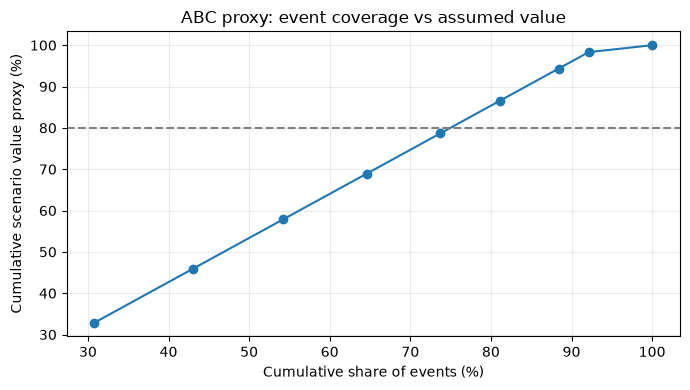

In [12]:
def make_abc_proxy(counts, dimension):
    if set(counts.columns)!={"column","value","rows"}:
        raise ValueError(f"Unexpected category-count schema: {counts.columns.tolist()}")
    if dimension not in set(counts["column"]):
        raise ValueError(f"No category dimension {dimension!r}")
    frame=counts.loc[counts["column"]==dimension,["value","rows"]].copy()
    frame=frame.groupby("value",dropna=False)["rows"].sum().rename("events").reset_index()
    # Attack_subType contains traffic/protocol names, not confirmed severity classes.
    # Scenario proxy only separates Normal from non-Normal; every non-Normal class gets 1.0.
    frame["scenario severity weight"]=np.where(frame["value"].astype(str).str.casefold()=="normal",0.2,1.0)
    frame["value proxy"]=frame["events"]*frame["scenario severity weight"]
    frame=frame.sort_values("value proxy",ascending=False).reset_index(drop=True)
    frame["cumulative event share"]=frame["events"].cumsum()/frame["events"].sum()
    frame["cumulative value proxy share"]=frame["value proxy"].cumsum()/frame["value proxy"].sum()
    crossing80=int(np.flatnonzero(frame["cumulative value proxy share"].to_numpy()>=.8)[0])
    crossing95=int(np.flatnonzero(frame["cumulative value proxy share"].to_numpy()>=.95)[0]) if (frame["cumulative value proxy share"]>=.95).any() else len(frame)-1
    frame["ABC"]=np.where(frame.index<=crossing80,"A",np.where(frame.index<=crossing95,"B","C"))
    return frame,crossing80

synthetic_counts=pd.DataFrame({"column":["Attack_subType"]*3,"value":["Normal","scan","udp"],"rows":[70,20,10]})
synthetic_abc,synthetic_cut=make_abc_proxy(synthetic_counts,"Attack_subType")
assert int(synthetic_abc["events"].sum())==100 and synthetic_abc.iloc[0]["value"]=="scan"
print("ABC synthetic smoke passed: one dimension grouped once, row count preserved, severity ranking applied.")
category_col=next((c for c in category_counts["column"].unique() if str(c).lower()=="attack_subtype"),None)
if category_col is None:
    raise ValueError("Source profile has no Attack_subType category")
abc,crossing_a=make_abc_proxy(category_counts,category_col)
assert int(abc["events"].sum())==row_count, f"Attack_subType counts do not sum to source rows: {abc['events'].sum()} vs {row_count}"
crossing_b = int(np.flatnonzero(abc["cumulative value proxy share"].to_numpy()>=.95)[0]) if (abc["cumulative value proxy share"]>=.95).any() else len(abc)-1
display(abc)
display(pd.DataFrame([{"event share at first 80% value crossing":float(abc.loc[crossing_a,"cumulative event share"]),"value share at A cutoff":float(abc.loc[crossing_a,"cumulative value proxy share"]),"A categories":crossing_a+1,"category dimension":category_col,"warning":"ABC proxy weights are assumptions, not observed losses"}]))
plt.figure(figsize=(7,4)); plt.plot(abc["cumulative event share"]*100,abc["cumulative value proxy share"]*100,marker="o"); plt.axhline(80,color="gray",ls="--"); plt.xlabel("Cumulative share of events (%)"); plt.ylabel("Cumulative scenario value proxy (%)"); plt.title("ABC proxy: event coverage vs assumed value"); plt.grid(alpha=.25); plt.tight_layout(); plt.savefig(RESULTS/"value_coverage_sensitivity.png",dpi=150); plt.show()
abc.to_csv(RESULTS/"abc_value_proxy.csv",index=False)

Для ценности объёма строим coverage curve по event population: категории A проходят realtime rules; B — быстрый micro-batch; C — холодный архив и выборочный backfill. Raw event всё равно сохраняется. Без adjudicated incident labels/class weights это не бизнес-эффект, поэтому кривая выше называется proxy и не используется как доказательство 80/20.

### 5.3. Мониторинг ценности и изменение за год

Операционные KPI: median/p95 MTTR, detection-to-ack, missed incidents, false alerts per shift, alert precision после расследования, доля incidents с корректным device/context, dropped/late event %, SLA availability, cost per 1k events. Incident owner подтверждает каждый пропуск/ложный сигнал. Pipeline KPI ежедневно, ROI ежеквартально; допущения пересмотреть раньше при смене rate card, event volume или incident pattern.

Year 2 учитывает рост числа инцидентов, потери в час и non-storage OPEX; долю сохранённого эффекта MTTR (.80/.90/1.00 для low/base/high) и incremental-effect share против конкурирующего/действующего baseline (.80/.90/1.00) — только явные сценарные допущения, не измеренные тренды или рыночная выручка. Цель MTTR −40% остаётся заданной целью, не фактом. Показана 3×3 sensitivity base-case по retention и доле добавочного эффекта; фактический incumbent improvement нужно измерить на сопоставимой группе/периоде и подставить. При retention 365 дней хранилище второго года рассчитано как steady state: полный баланс данных за 365 дней × 12 месяцев тарифа Standard. Тариф удерживается на уровне иллюстративной ставки года 1; первый год использует средний растущий баланс по календарным месяцам. Пересчитать по закрытым инцидентам через 12 месяцев.

## 6. Выбор технологий и архитектура

### 6.1. Сравнение вариантов и выбор

| Слой | Варианты | Рекомендация для данного сценария | Ограничения и триггер изменения |
|---|---|---|---|
| Raw/curated storage | Локальные CSV; PostgreSQL; HDFS; Yandex Object Storage (S3 API) + Parquet | Yandex-compatible object storage: immutable raw + curated Parquet; schema catalog | Иллюстративный тариф меняется; учитывать requests/egress/replication. PostgreSQL ограничен raw log volume; HDFS даёт лишнюю эксплуатацию для старта |
| Event intake | HTTP/MQTT; Kafka-compatible broker; managed queue | Apache Kafka-compatible durable broker, keyed by stable asset/event ID, timestamp в payload | CSV имеет Device_Name category, но нет stable asset UUID, event ID, event_time/ingest_time; до upstream contract нет production alert |
| Compute | Pandas/Polars; Spark Structured Streaming; Flink | Конкретный pilot: Kafka consumer + bounded Python streaming worker для правила/anomaly alert ≤5s; DuckDB для offline profile/backfill; Prefect для scheduled offline jobs | Worker capacity и 5s SLA должны пройти load/failover test; Spark — batch/backfill; Flink — альтернатива при stateful event-time windows/росте потока |
| ML / anomaly | Static rules; robust statistical detector; supervised model | Start with rules + robust baselines; MLflow для versioned evaluation | No incident ground truth in dataset; label leakage if Attack/label is used as feature; feature store не нужен до online/offline parity requirement |
| Orchestration | Cron; Prefect; Airflow; managed workflow | Prefect для backfill, daily profile и плановых data-quality jobs; event loop работает как long-running service, не в hourly DAG | Airflow добавляет операционные затраты для одной job; пересмотреть при росте зависимостей |
| Text logs | Regex/grok/parser; NLP pipeline | Versioned parser + schema validation + quarantine first | NLP only after representative free-text and tested incremental value |

| Сравнение | pandas/DuckDB batch | Kafka + bounded Python stream (pilot) | Spark batch/Structured Streaming | Flink stateful streaming |
|---|---|---|---|---|
| Латентность | Минуты/часы для периодического расчёта; DuckDB эффективно для offline запросов | Секунды при ограниченной очереди и успешном load test | Batch/backfill — хороший throughput; micro-batch не гарантирует 5 s end-to-end | Низкая задержка и event-time state при корректном provision |
| Стоимость compute | Минимальная для single node, но предел RAM/одного worker | Умеренная при небольшом worker; broker — постоянная стоимость | Выше из-за cluster/shuffle/runtime overhead | Выше из-за stateful cluster и on-call сложности |
| Эксплуатация | Низкая | Средняя: offsets, backpressure, idempotency, DLQ | Высокая для небольшого проекта | Самая высокая для старта |
| Решение | Оставить для offline profile/backfill | Выбран pilot после shadow load/failure gates | Резерв для batch-scale/backfill | Миграция, если нужны сложные event-time windows или простой worker не держит SLA |

**Почему этот выбор соответствует 5V:** Parquet уменьшает измеренное analytical storage; durable stream поддерживает alert SLA; versioned parsing сохраняет variety raw; quality gates отправляют повреждённые события в quarantine; приоритетные сигналы должны снижать MTTR. Сравнение относится к рассматриваемому сценарию, а не является универсальным рейтингом.

### 6.2. Схема и ресурсы

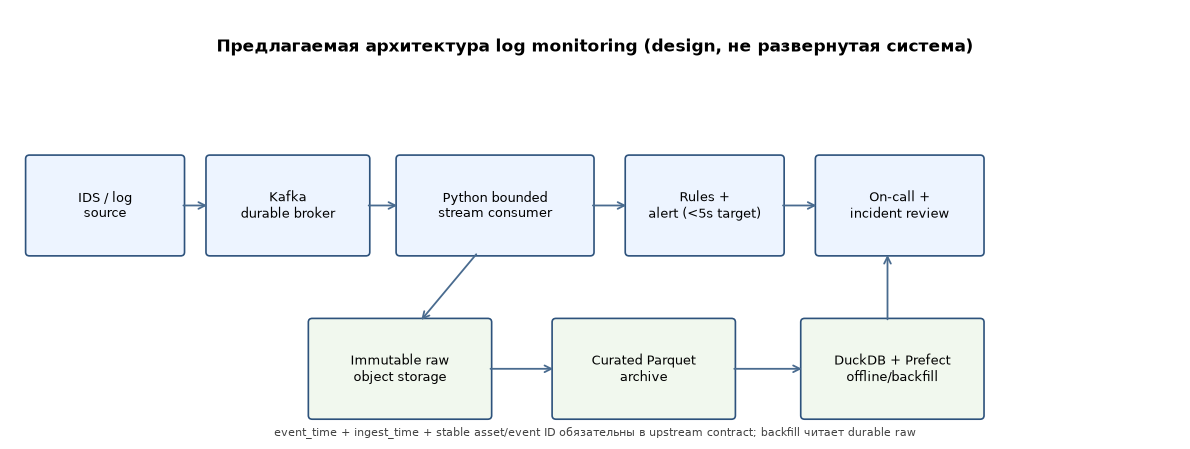

In [13]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig, ax = plt.subplots(figsize=(12,4.6)); ax.set_xlim(0,12); ax.set_ylim(0,4.6); ax.axis("off")
boxes=[(0.2,2.0,1.55,1.0,"IDS / log\nsource"),(2.05,2.0,1.6,1.0,"Kafka\ndurable broker"),(4.0,2.0,1.95,1.0,"Python bounded\nstream consumer"),(6.35,2.0,1.55,1.0,"Rules +\nalert (<5s target)"),(8.3,2.0,1.65,1.0,"On-call +\nincident review"),(3.1,.25,1.8,1.0,"Immutable raw\nobject storage"),(5.6,.25,1.8,1.0,"Curated Parquet\narchive"),(8.15,.25,1.8,1.0,"DuckDB + Prefect\noffline/backfill")]
for x,y,w,h,label in boxes:
 p=FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.04",fc="#edf4ff" if y>1 else "#f1f8ee",ec="#2d527c",lw=1.2); ax.add_patch(p); ax.text(x+w/2,y+h/2,label,ha="center",va="center",fontsize=9)
for a,b in [((1.75,2.5),(2.05,2.5)),((3.65,2.5),(4.0,2.5)),((5.95,2.5),(6.35,2.5)),((7.9,2.5),(8.3,2.5)),((4.8,2.0),(4.2,1.25)),((4.9,.75),(5.6,.75)),((7.4,.75),(8.15,.75)),((9.0,1.25),(9.0,2.0))]:
 ax.add_patch(FancyArrowPatch(a,b,arrowstyle="->",mutation_scale=12,color="#496b8f",lw=1.3))
ax.text(6,4.15,"Предлагаемая архитектура log monitoring (design, не развернутая система)",ha="center",fontsize=12,weight="bold")
ax.text(6,.03,"event_time + ingest_time + stable asset/event ID обязательны в upstream contract; backfill читает durable raw",ha="center",fontsize=8,color="#444")
fig.tight_layout(); fig.savefig(RESULTS/"architecture.png",dpi=160,bbox_inches="tight"); plt.show()

**Численный provisional sizing:** при целевых 2000 EPS и 2 ms CPU на событие требуется `ceil(2000 × 0.002 / 0.65) = 7 vCPU` при верхней загрузке CPU 65%; округляем worker до 8 vCPU. Memory budget: runtime 2 GiB + key/window state 4 GiB + 60-second buffer `2000 × 60 × 1.5 KiB × 2 copies ≈0.34 GiB`; с 30% запасом около 8.3 GiB, выбираем 16 GiB. Эти CPU ms/record, state memory, 1.5 KiB/event и 60-second buffer — сценарные допущения, не бенчмарк; пилот должен подтвердить их нагрузочным тестом. 30 минут peak outage копят примерно 1.8 млн событий; при 2000 EPS processing capacity и продолжающемся 1000 EPS входе расчётный drain — 30 минут. Локальный spool 100 GiB больше outage backlog; retention в object storage — 30 дней hot и 12 месяцев archive. Broker replication factor 3 включать после проверки стоимости/доступности.

### 6.3. План миграции, roadmap и риски

| Месяц | Этап / deliverable | Численный критерий успеха | Gate / rollback |
|---|---|---|---|
| 1 | Договориться об event_time, ingest_time, stable asset UUID, event_id, severity и incident ledger; `Device_Name` из CSV — категория, но не гарантированный уникальный ключ; собрать реальные raw logs | ≥7 дней репрезентативных логов; 100% schema fields имеют owner/definition | Без времени/ID не включать real-time alert |
| 2 | Parser + raw immutable archive + quarantine | ≥99.9% parse success на test corpus; 100% raw сохраняется | При schema drift — quarantine, предыдущий parser remains active |
| 3 | Offline baseline rules и labelled replay | На adjudicated incidents: recall target ≥95% и ≤2 false alerts/shift (targets to validate) | Не внедрять ML без leakage review и holdout by time/device |
| 4 | Shadow stream, latency/load/failure injection | p95≤5s, p99≤30s, ≥2× peak throughput, 30-min peak backlog drains ≤30min при продолжающемся 1000 EPS input | Shadow mode, rollback на durable queue/raw replay |
| 5 | Ограниченный canary, on-call runbook, dashboard | ≥99.5% alert service availability; MTTR −20% на ≥30 подтверждённых инцидентах (interim gate) | Автоматический rollback при ложных тревогах >2/shift или потерях >0.1% |
| 6 | Expand and financial checkpoint | MTTR −40% на ≥50 incidents / matched cohort; missed-event rate <0.1%; positive unit economics | Если confidence sample недостаточен — продлить shadow/canary |

| Риск | Вероятность/влияние | Митигация и контроль |
|---|---|---|
| Нет event time / stable asset ID / подтверждённых инцидентов (`Device_Name` не гарантирует уникальность) | Высокое/блокирует правильную диагностику | Data contract как Month 1 exit gate; capture ingest time and immutable raw |
| False alarms утомляют on-call | Среднее/высокое | Shadow mode, per-shift false-alert budget, dedup/cooldown, human confirmation |
| Dropped/duplicate/late events | Среднее/высокое | Durable ack, idempotency, sequence/watermark, 30-minute replay tests |
| Attack labels leak into evaluation | Среднее/высокое | No Attack/label features; time/device holdout, independent incident labels |
| Parser/schema drift | Высокое/среднее | Versioned parser, contract tests, quarantine, safe rollback |
| Costs exceed avoided loss | Среднее/высокое | Cost per 1k events, budget alert, monthly unit economics, stop gates |
| Sensitive log data exposed | Среднее/высокое | Minimize fields, encryption, RBAC, retention/deletion policy, audit |

## 7. Выводы по пяти V — факты этого прогона и границы выводов

| V | Фактический результат | Интерпретация и ограничение |
|---|---|---|
| **Volume** | 7 062 606 строк × 27 полей; исходный CSV — 1 678 174 220 байт (1.563 GiB). Parquet — 458 856 825 байт (−72.7% к CSV), Avro — 370 939 358 байт (−77.9%); полные проверки round-trip прошли для обоих форматов. | Avro занимает меньше места. Для аналитических запросов выбран Parquet из-за columnar layout, а не как формат с минимальным размером. Замеры чтения не сравниваются: Parquet read timing не подтверждает полный scan. |
| **Velocity** | CSV не содержит timestamp. В заданном replay-сценарии: 100 EPS обычно, 1 000 EPS в burst, среднее 156.25 EPS; seed-генерация дала максимум 300 708 событий за 5 минут (1 002.36 EPS) и CV 1.397. | Это симуляция, не измеренная скорость датчиков. При outage 30 минут моделируется 1.8 млн событий (~0.11 GiB Parquet proxy); расчётный drain — 30 минут при 2 000 EPS worker и продолжающемся входе 1 000 EPS. |
| **Variety** | 23 числовых признака, 3 категориальных поля, отдельная метка `label`; timestamp-колонок и вложенного JSON — 0. Текстовые значения трёх категориальных полей занимают 15.76% исходных CSV bytes. | Эти значения не измеряют долю неструктурированных production logs. Файл — плоская таблица признаков IDS, а не сырой текст логов. |
| **Veracity** | Пропусков — 0; избыточных полных повторов — 621 659; выходов `HH_L0.1_pcc` за [-1,1] — 2 791, `HpHp_L0.1_pcc` — 1 844; несоответствий `Attack`/`label` — 0. Great Expectations: 142/142 ожиданий пройдены; отрицательный контроль отверг испорченную метку. | Счётчики двух PCC-полей могут пересекаться; их нельзя складывать как число уникальных строк. Повторы не удалены: CSV не даёт event ID, а одинаковые признаки могут быть легитимным повторным трафиком. |
| **Value** | Модельные сценарии: base — gross avoided loss 4 800 000 ₽, net первого года 2 322 313 ₽, ROI 93.73%, окупаемость 4.09 месяца; net второго года 2 822 460 ₽. | Это расчёт на сценарных инцидентах, стоимости, ложных тревогах, расходах и сохранении эффекта, а не фактически достигнутая экономия. Цель MTTR −40% не измерялась. |

Сводка финансовой модели при текущих предположениях:

| Сценарий | Валовой предотвращённый ущерб, год 1 | Инвестиции и расходы, год 1 | Чистый результат, год 1 | ROI, год 1 | Окупаемость | Чистый результат, год 2 |
|---|---:|---:|---:|---:|---:|---:|
| Low | 480 000 ₽ | 2 526 329 ₽ | −2 046 329 ₽ | −81.00% | нет при этих вводных | −802 492 ₽ |
| Base | 4 800 000 ₽ | 2 477 687 ₽ | 2 322 313 ₽ | 93.73% | 4.09 мес. | 2 822 460 ₽ |
| High | 21 600 000 ₽ | 2 849 153 ₽ | 18 750 847 ₽ | 658.12% | 0.61 мес. | 22 945 897 ₽ |

Финансовые суммы — сценарные оценки, не наблюдаемая бизнес-ценность. Для реального ROI нужны подтверждённые инциденты, базовый MTTR, стоимость простоя, false-alert workload и фактические тарифы.

**Рекомендация:** оставить этот датасет для воспроизводимого профиля качества и размера IDS-данных. Для мониторинга логов сначала собрать отдельный поток с временем события, стабильным ID устройства/события и подтверждённым журналом инцидентов. Хранить исходные записи неизменными, структурированные результаты — в Parquet. Начать с shadow-проверки правил и парсера; переходить к активным алертам после проверки p95 ≤5 секунд, p99 ≤30 секунд, пропускной способности не менее 2× пика и восстановления после сбоя. Полная таблица покрытия задания находится в [`requirements_checklist.md`](requirements_checklist.md).

## Источники, измерения и допущения

- **Датасет:** [Kaggle: IoT Dataset for Intrusion Detection Systems (IDS)](https://www.kaggle.com/datasets/azalhowaide/iot-dataset-for-intrusion-detection-systems-ids), `BoTNeTIoT-L01-v2.csv`. В этом прогоне прочитан локальный CSV размером 1 678 174 220 байт, 7 062 606 строк; SHA-256: `e3cb8a91f0fb99afb81fefe55ee04743ed67dd7ec9ea4d119cf2a71c8a1a494d`.
- **Объектное хранилище:** [официальные примеры тарифов Yandex Object Storage](https://yandex.cloud/ru/docs/storage/pricing), проверены 20.10.2026: Standard — 2.376 ₽/GiB·месяц, Ice — 0.6336 ₽/GiB·месяц, 1 GiB Standard в месяц бесплатно, Ice — минимальный срок 12 месяцев, НДС включён в примеры. Это ориентировочные примеры, не коммерческая котировка; операции, egress и репликация не включены.
- **Измеренные данные:** фактическая схема, размеры сериализаций, quality metrics и артефакты лежат в `lab1/results/`. Полные round-trip Parquet и Avro проверены на всех 7 062 606 строках; CSV — исходный файл и baseline.
- **Сценарные вводные:** 100 EPS обычная нагрузка, 1 000 EPS burst, синтетическое расписание пиков, 1.5 KiB сырого syslog-события, 30-дневный hot retention, стоимость инцидента и ложного алерта, размер worker и стоимость внедрения. Это нужно заменить операционными измерениями до инвестиционного решения.
- **Ограничение времени:** в CSV нет event timestamp. `HH_jit_L0.1_mean` — числовой jitter-признак, а не дата/время.
- **Запуск:** runner выполнил 13 code cells; профиль существующего датасета cache переиспользован без повторного полного анализа; в outputs notebook сохранены 4 inline PNG-графика/схемы.